# Naive Bayes (Gaussian)

Trains GaussianNB, evaluates, examines learned parameters, computes discrimination scores, shows probability estimates, and saves model.

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from IPython.display import display
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder
import joblib

from schema_utils import detect_feature_columns, build_feature_matrix



In [2]:
# 2. Data Loading - use train/test CSVs
import os
import pandas as pd
DATA_DIR = os.path.join('..','datasets')
TRAIN_PATH = os.path.join(DATA_DIR, 'training_data_train_cat.csv')
TEST_PATH = os.path.join(DATA_DIR, 'training_data_test_cat.csv')
if not os.path.exists(TRAIN_PATH) or not os.path.exists(TEST_PATH):
    raise FileNotFoundError("Missing train/test CSVs in ../datasets: training_data_train.csv and training_data_test.csv")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
from schema_utils import detect_feature_columns
schema = detect_feature_columns(df_train)
if not schema['label_col']:
    raise ValueError('No label column detected. Expected one of: label/class/target')
label_col = schema['label_col']
print('Train size:', len(df_train), 'Test size:', len(df_test))
print('Train balance:', df_train[label_col].value_counts(normalize=True))
print('Test balance:', df_test[label_col].value_counts(normalize=True))



Train size: 1661 Test size: 483
Train balance: label
human      0.493076
nothing    0.338350
cat        0.168573
Name: proportion, dtype: float64
Test balance: label
human      0.432712
nothing    0.422360
cat        0.144928
Name: proportion, dtype: float64


In [3]:
# 3-4. Features + Split (pre-split train/test, train-only fit)
import numpy as np
from schema_utils import build_feature_matrix
feature_cols = schema['classic_feature_cols']
X_train_all = build_feature_matrix(df_train, feature_cols)
X_test_all = build_feature_matrix(df_test, feature_cols)
# Fill NaNs using training medians
train_medians = np.nanmedian(X_train_all, axis=0)
X_train_all = np.where(np.isnan(X_train_all), train_medians, X_train_all)
X_test_all = np.where(np.isnan(X_test_all), train_medians, X_test_all)
# Labels
y_str_train = df_train[label_col].astype(str).values
y_str_test = df_test[label_col].astype(str).values
from sklearn.preprocessing import LabelEncoder, StandardScaler
le = LabelEncoder()
y_train = le.fit_transform(y_str_train)
y_test = le.transform(y_str_test)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_all)
X_test = scaler.transform(X_test_all)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Classes:', list(le.classes_))
# Map 'nothing' class index for threshold fallback
classes = list(le.classes_)
idx_nothing = next((i for i, c in enumerate(classes) if c.lower() == 'nothing'), None)
print('idx_nothing:', idx_nothing)



Train shape: (1661, 46) Test shape: (483, 46)
Classes: ['cat', 'human', 'nothing']
idx_nothing: 2


Training accuracy: 0.9969897652016857
Test accuracy: 0.9834368530020704
Confusion matrix: [[ 70   0   0]
 [  0 208   1]
 [  0   7 197]]
              precision    recall  f1-score   support

         cat       1.00      1.00      1.00        70
       human       0.97      1.00      0.98       209
     nothing       0.99      0.97      0.98       204

    accuracy                           0.98       483
   macro avg       0.99      0.99      0.99       483
weighted avg       0.98      0.98      0.98       483



,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,...,f37,f38,f39,f40,f41,f42,f43,f44,f45,f46
class,,,,,,,,,,,,,,,,,,,,,
cat,0.629571,0.047054,-0.078802,-0.250829,-0.349939,-0.401648,-0.426046,-0.365327,-0.145199,0.530997,...,0.235781,-0.414366,0.000597,0.004354,-0.130130,1.363517,-0.585429,1.644823,-0.551257,0.485390
human,-0.108252,0.163366,0.246570,0.310786,0.372406,0.404749,0.431205,0.366671,0.142201,-0.396951,...,-0.265547,-0.353969,-0.001331,0.000963,0.075077,0.016348,0.959543,-0.129450,0.648384,-0.835774
nothing,-0.155910,-0.261515,-0.320064,-0.327939,-0.368358,-0.389729,-0.416128,-0.352335,-0.134888,0.313921,...,0.269510,0.722283,0.001641,-0.003573,-0.044576,-0.703156,-1.106665,-0.630838,-0.670239,0.976138


,feature,score
12,f13,1.576547
43,f44,0.953119
42,f43,0.769760
41,f42,0.733743
33,f34,0.728826
34,f35,0.695402
35,f36,0.677966
45,f46,0.585481
28,f29,0.548123
30,f31,0.529041


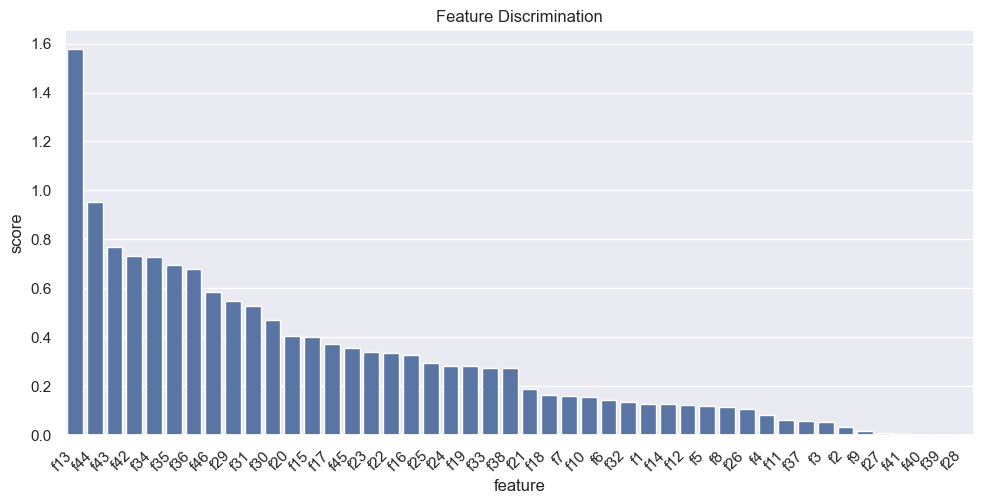

Probabilities (first 5 samples):
   cat  human  nothing
0  0.0    1.0      0.0
1  0.0    1.0      0.0
2  0.0    1.0      0.0
3  0.0    1.0      0.0
4  0.0    1.0      0.0
Predicted labels: ['human' 'human' 'human' 'human' 'human']
Saved model as naive_bayes_cat.pkl


In [4]:

from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
training_accuracy = nb.score(X_train, y_train)
proba = nb.predict_proba(X_test)
y_pred_max = np.argmax(proba, axis=1)
y_pred_conf = np.max(proba, axis=1)
# Require 70% confidence; fallback to 'nothing' when low confidence
y_pred = np.where(y_pred_conf >= 1.0, y_pred_max, (idx_nothing if idx_nothing is not None else y_pred_max))
test_accuracy = accuracy_score(y_test, y_pred)
print('Training accuracy:', training_accuracy)
print('Test accuracy:', test_accuracy)

print('Confusion matrix:', confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))

# Learned parameters per class
means = nb.theta_  # class means (n_classes, n_features)
try:
    variances = nb.var_
except AttributeError:
    variances = nb.sigma_
stds = np.sqrt(variances)
params_df = pd.DataFrame(means, columns=feature_cols)
params_df['class'] = le.classes_
display(params_df.set_index('class'))

# Discrimination score: variance of class means per feature
disc_scores = np.var(means, axis=0)
disc_df = pd.DataFrame({'feature': feature_cols, 'score': disc_scores}).sort_values('score', ascending=False)
display(disc_df)
plt.figure(figsize=(10,5)); sns.barplot(x='feature', y='score', data=disc_df);
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.title('Feature Discrimination'); plt.show()

# Probability estimates for sample predictions
probs = nb.predict_proba(X_test[:5])
print('Probabilities (first 5 samples):')
print(pd.DataFrame(probs, columns=le.classes_))
print('Predicted labels:', le.inverse_transform(nb.predict(X_test[:5])))

# Save model
best_model = GaussianNB()
best_model.fit(np.vstack([X_train,X_test]), np.hstack([y_train,y_test]))
joblib.dump(best_model, os.path.join('..','models','naive_bayes_cat.pkl'))
print('Saved model as naive_bayes_cat.pkl')


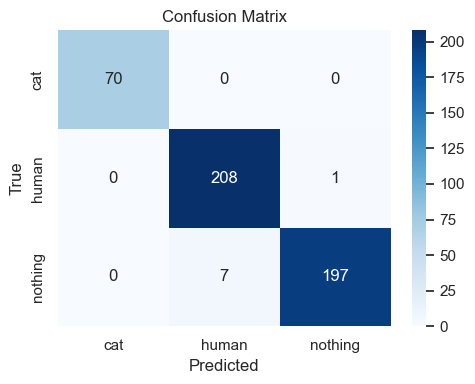

              precision    recall  f1-score   support

         cat       1.00      1.00      1.00        70
       human       0.97      1.00      0.98       209
     nothing       0.99      0.97      0.98       204

    accuracy                           0.98       483
   macro avg       0.99      0.99      0.99       483
weighted avg       0.98      0.98      0.98       483



In [5]:

# Confusion Matrix - Visualize mistakes
from sklearn.metrics import confusion_matrix, classification_report
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(le.classes_), yticklabels=list(le.classes_))
plt.title('Confusion Matrix')
plt.ylabel('True'); plt.xlabel('Predicted')
plt.tight_layout(); plt.show()
print(classification_report(y_test, y_pred, target_names=list(le.classes_)))
